<a href="https://colab.research.google.com/github/ddev3r/Machine-learning/blob/main/%D0%A1%D1%82%D0%B0%D1%80%D0%BE%D0%B2%D0%BE%D0%B9%D1%82%D0%BE%D0%B2_%D0%9B%D0%A0_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Завдання №1

№1 Завантаження та підготовка даних

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

boston = fetch_openml(data_id=531, as_frame=True, parser="auto")
X = boston.data.astype(float)
y = boston.target.astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

# Генерація поліноміальних ознак 2-го степеня (104)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(f"Початкова кількість ознак:             {X.shape[1]}")
print(f"Кількість ознак після поліномізації:   {X_train_poly.shape[1]}")
print(f"Кількість зразків у навчальній вибірці: {X_train_poly.shape[0]}")
print(f"Кількість зразків у тестовій вибірці:   {X_test_poly.shape[0]}")

Початкова кількість ознак:             13
Кількість ознак після поліномізації:   104
Кількість зразків у навчальній вибірці: 404
Кількість зразків у тестовій вибірці:   102


№2 Побудова регресійної моделі

In [4]:
# Побудова та навчання лінійної моделі
baseline_model = make_pipeline(StandardScaler(), LinearRegression())
baseline_model.fit(X_train_poly, y_train)

y_test_pred_base = baseline_model.predict(X_test_poly)

base_test_mse = mean_squared_error(y_test, y_test_pred_base)
base_test_r2 = r2_score(y_test, y_test_pred_base)

print("Базова лінійна регресія (Тест)")
print(f"Test MSE: {base_test_mse:.2f}")
print(f"Test R²:  {base_test_r2:.4f}")

Базова лінійна регресія (Тест)
Test MSE: 2714.06
Test R²:  0.5692


№3 Аналіз перенавчання

In [7]:
# Оцінка базової моделі
y_train_pred_base = baseline_model.predict(X_train_poly)

base_train_mse = mean_squared_error(y_train, y_train_pred_base)
base_train_r2 = r2_score(y_train, y_train_pred_base)

print("Діагностика перенавчання")
print(f"Train MSE: {base_train_mse:.2f}  та  Test MSE: {base_test_mse:.2f}")
print(f"Train R²:  {base_train_r2:.4f}  та  Test R²:  {base_test_r2:.4f}")
print(f"Зростання MSE на тесті: +{base_test_mse - base_train_mse:.2f}")
print(f"Падіння R² на тесті:    -{base_train_r2 - base_test_r2:.4f}")

Діагностика перенавчання
Train MSE: 2404.58  та  Test MSE: 2714.06
Train R²:  0.5880  та  Test R²:  0.5692
Зростання MSE на тесті: +309.48
Падіння R² на тесті:    -0.0188


№4 Запобігання перенавчанню

In [10]:
# Налаштування крос-валідації
kf = KFold(n_splits=5, shuffle=True, random_state=123)
base_cv_mse = -cross_val_score(
    baseline_model, X_train_poly, y_train, cv=kf, scoring="neg_mean_squared_error"
).mean()

# 1. Підбір alpha для L2-регуляризації (Ridge)
ridge_alphas = np.logspace(-2, 4, 40)
ridge_train_mse, ridge_test_mse, ridge_cv_mse = [], [], []

for alpha in ridge_alphas:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha, random_state=42))
    model.fit(X_train_poly, y_train)
    ridge_train_mse.append(mean_squared_error(y_train, model.predict(X_train_poly)))
    ridge_test_mse.append(mean_squared_error(y_test, model.predict(X_test_poly)))
    cv_val = -cross_val_score(
        model, X_train_poly, y_train, cv=kf, scoring="neg_mean_squared_error"
    ).mean()
    ridge_cv_mse.append(cv_val)

best_ridge_idx = np.argmin(ridge_cv_mse)
best_ridge_alpha = ridge_alphas[best_ridge_idx]

# 2. Підбір alpha для L1-регуляризації (Lasso)
lasso_alphas = np.logspace(-2, 1.5, 40)
lasso_train_mse, lasso_test_mse, lasso_cv_mse = [], [], []

for alpha in lasso_alphas:
    model = make_pipeline(
        StandardScaler(), Lasso(alpha=alpha, max_iter=30000, tol=1e-3, random_state=123)
    )
    model.fit(X_train_poly, y_train)
    lasso_train_mse.append(mean_squared_error(y_train, model.predict(X_train_poly)))
    lasso_test_mse.append(mean_squared_error(y_test, model.predict(X_test_poly)))
    cv_val = -cross_val_score(
        model, X_train_poly, y_train, cv=kf, scoring="neg_mean_squared_error"
    ).mean()
    lasso_cv_mse.append(cv_val)

best_lasso_idx = np.argmin(lasso_cv_mse)
best_lasso_alpha = lasso_alphas[best_lasso_idx]

print(f"Оптимальне alpha для Ridge (L2): {best_ridge_alpha:.4f} (CV MSE = {ridge_cv_mse[best_ridge_idx]:.2f})")
print(f"Оптимальне alpha для Lasso (L1): {best_lasso_alpha:.4f} (CV MSE = {lasso_cv_mse[best_lasso_idx]:.2f})")

Оптимальне alpha для Ridge (L2): 1.4251 (CV MSE = 11.46)
Оптимальне alpha для Lasso (L1): 0.0186 (CV MSE = 11.29)


№5 Оцінка результатів

In [11]:
# Навчання фінальних моделей з оптимальними alpha
best_ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha, random_state=123))
best_ridge.fit(X_train_poly, y_train)

best_lasso = make_pipeline(
    StandardScaler(), Lasso(alpha=best_lasso_alpha, max_iter=30000, tol=1e-3, random_state=123)
)
best_lasso.fit(X_train_poly, y_train)

# Кількість ненульових ознак
lasso_nonzero = np.sum(best_lasso.named_steps["lasso"].coef_ != 0)

comparison_df = pd.DataFrame({
    "Модель": [
        "LinearRegression (базова)",
        f"Ridge L2 (alpha={best_ridge_alpha:.2f})",
        f"Lasso L1 (alpha={best_lasso_alpha:.2f})"
    ],
    "Train MSE": [
        base_train_mse,
        mean_squared_error(y_train, best_ridge.predict(X_train_poly)),
        mean_squared_error(y_train, best_lasso.predict(X_train_poly))
    ],
    "CV MSE": [
        base_cv_mse,
        ridge_cv_mse[best_ridge_idx],
        lasso_cv_mse[best_lasso_idx]
    ],
    "Test MSE": [
        base_test_mse,
        mean_squared_error(y_test, best_ridge.predict(X_test_poly)),
        mean_squared_error(y_test, best_lasso.predict(X_test_poly))
    ],
    "Train R²": [
        base_train_r2,
        r2_score(y_train, best_ridge.predict(X_train_poly)),
        r2_score(y_train, best_lasso.predict(X_train_poly))
    ],
    "Test R²": [
        base_test_r2,
        r2_score(y_test, best_ridge.predict(X_test_poly)),
        r2_score(y_test, best_lasso.predict(X_test_poly))
    ],
    "Активні ознаки": [X_train_poly.shape[1], X_train_poly.shape[1], lasso_nonzero]
})

print(comparison_df.to_string(index=False))

                   Модель   Train MSE    CV MSE    Test MSE  Train R²  Test R²  Активні ознаки
LinearRegression (базова) 2404.578951 21.485090 2714.056619  0.587982 0.569209             104
    Ridge L2 (alpha=1.43)    7.345199 11.459805   17.914751  0.913301 0.783470             104
    Lasso L1 (alpha=0.02)    8.242743 11.286029   21.262817  0.902707 0.743003              46


№6 Візуалізація та висновки

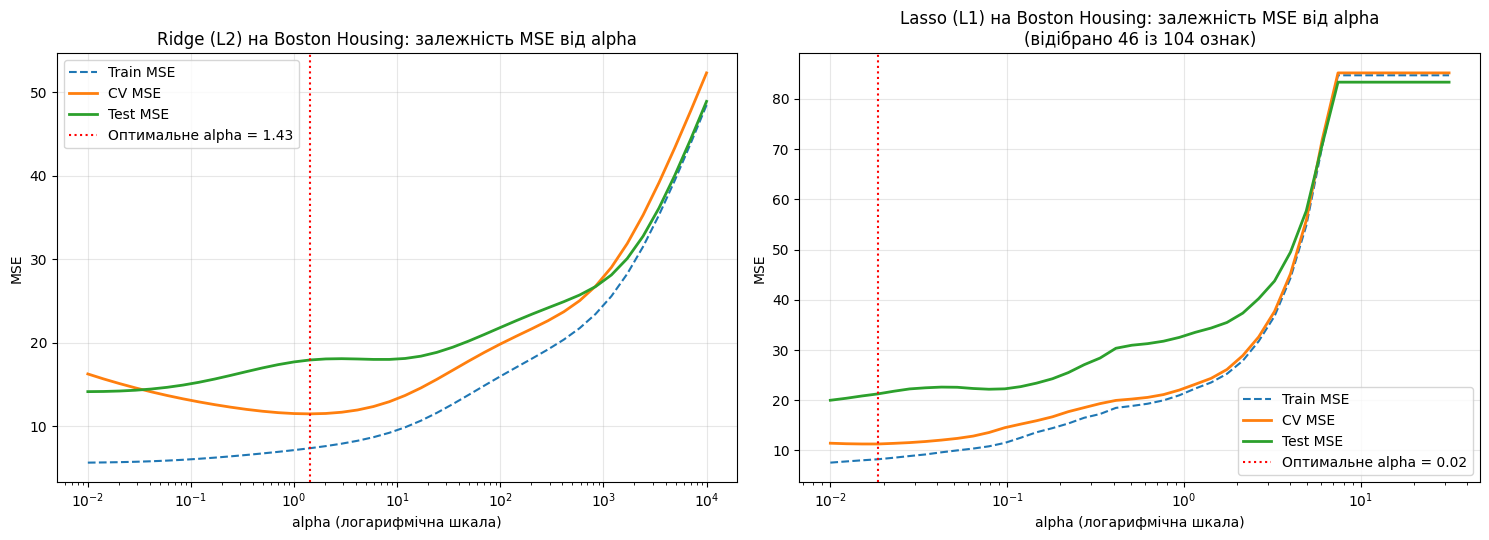

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Ridge (L2)
axes[0].plot(ridge_alphas, ridge_train_mse, label="Train MSE", linestyle="--")
axes[0].plot(ridge_alphas, ridge_cv_mse, label="CV MSE", linewidth=2)
axes[0].plot(ridge_alphas, ridge_test_mse, label="Test MSE", linewidth=2)
axes[0].axvline(best_ridge_alpha, color="red", linestyle=":", label=f"Оптимальне alpha = {best_ridge_alpha:.2f}")
axes[0].set_xscale("log")
axes[0].set_title("Ridge (L2) на Boston Housing: залежність MSE від alpha")
axes[0].set_xlabel("alpha (логарифмічна шкала)")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Lasso (L1)
axes[1].plot(lasso_alphas, lasso_train_mse, label="Train MSE", linestyle="--")
axes[1].plot(lasso_alphas, lasso_cv_mse, label="CV MSE", linewidth=2)
axes[1].plot(lasso_alphas, lasso_test_mse, label="Test MSE", linewidth=2)
axes[1].axvline(best_lasso_alpha, color="red", linestyle=":", label=f"Оптимальне alpha = {best_lasso_alpha:.2f}")
axes[1].set_xscale("log")
axes[1].set_title(f"Lasso (L1) на Boston Housing: залежність MSE від alpha\n(відібрано {lasso_nonzero} із {X_train_poly.shape[1]} ознак)")
axes[1].set_xlabel("alpha (логарифмічна шкала)")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Висновок: На датасеті Boston Housing із розширеним простором поліноміальних ознак звичайна лінійна регресія демонструє виражене перенавчання: високу точність на навчальній вибірці при значно гірших результатах на тестовій.

На графіках простежується зміна режимів моделі залежно від alpha: за надто малих значень зберігається висока дисперсія (перенавчання), в зоні мінімуму кривої CV MSE досягається найкраща узагальнювальна здатність, а за надто великих alpha модель переходить у недонавчання (underfitting).

Застосування L1/L2 регуляризації у поєднанні з крос-валідацією суттєво підвищило якість прогнозування на тестовій вибірці порівняно з базовою моделлю.

Завдання №2

№1 Виконати кластерізацію даних.

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Масштабуєвання ознак
scaler_cluster = StandardScaler()
X_scaled = scaler_cluster.fit_transform(X)

print(f"Дані готові до кластеризації: {X_scaled.shape[0]} об'єктів, {X_scaled.shape[1]} ознак")

Дані готові до кластеризації: 506 об'єктів, 13 ознак


№2 Затосувати метод ліктя або метод силуєтів. (Силуетів)

Оптимальна кількість кластерів за методом силуетів: k = 2 (Silhouette Score = 0.3601)


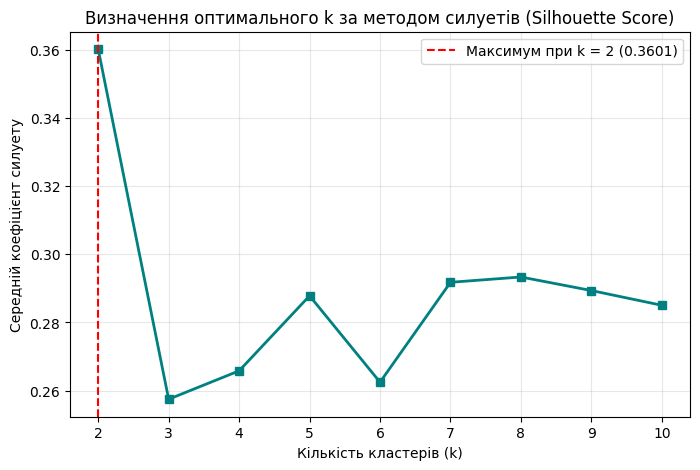

In [16]:
k_range = range(2, 11)
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

optimal_k = list(k_range)[np.argmax(silhouette_scores)]
best_sil = max(silhouette_scores)

print(f"Оптимальна кількість кластерів за методом силуетів: k = {optimal_k} (Silhouette Score = {best_sil:.4f})")

plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, marker="s", color="teal", linewidth=2)
plt.axvline(optimal_k, color="red", linestyle="--", label=f"Максимум при k = {optimal_k} ({best_sil:.4f})")
plt.title("Визначення оптимального k за методом силуетів (Silhouette Score)")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Середній коефіцієнт силуету")
plt.xticks(list(k_range))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

№3 Зробити візуалізацію кластерів.

         Кількість_обєктів  Середня_ціна_тис_дол
Кластер                                         
0                      329             25.749848
1                      177             16.553107


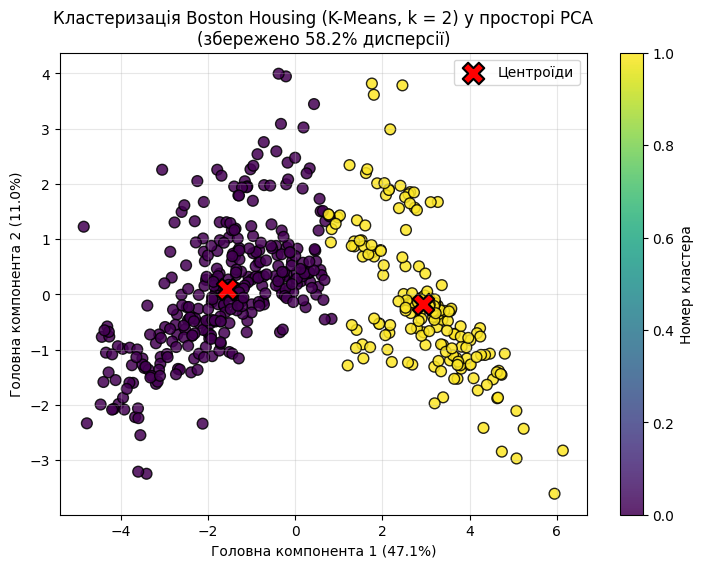

In [17]:
kmeans_final = KMeans(n_clusters=optimal_k, n_init=10, random_state=123)
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Аналіз складу кластерів та середньої вартості житла
cluster_summary = pd.DataFrame({
    "Кластер": cluster_labels,
    "Вартість житла (MEDV)": y.values
}).groupby("Кластер").agg(
    Кількість_обєктів=("Вартість житла (MEDV)", "count"),
    Середня_ціна_тис_дол=("Вартість житла (MEDV)", "mean")
)
print(cluster_summary)

# Зниження розмірності до 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans_final.cluster_centers_)
explained_var = pca.explained_variance_ratio_.sum() * 100

plt.figure(figsize=(8.5, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=cluster_labels, cmap="viridis", s=60, alpha=0.85, edgecolors="k"
)
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c="red", marker="X", s=240, edgecolors="black", linewidths=1.5, label="Центроїди"
)
plt.title(f"Кластеризація Boston Housing (K-Means, k = {optimal_k}) у просторі PCA\n(збережено {explained_var:.1f}% дисперсії)")
plt.xlabel(f"Головна компонента 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"Головна компонента 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.colorbar(scatter, label="Номер кластера")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Висновок: У другому завданні було виконано кластеризацію датасету Boston housing. Визначенj оптимального k за методом силуетів: Найвище значення середнього коефіцієнта силуету досягається при k = 2, що вказує на найкраще поєднання компактності об'єктів усередині кластерів та відстані між сусідніми групами. При подальшому збільшенні $k$ коефіцієнт силуету знижується через штучне дроблення однорідних груп.